## Comparación de Crop2, Crop3 y Crop4

Comparación de exactitud, SSIM y PSNR con el mismo CVAE y las mismas imágenes por corrida. (cro2 y 3 corregidos)

In [ ]:

import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../..")))
from project.loader import Loader
from project.CROP.models.crop2 import Crop2
from project.CROP.models.crop3 import Crop3
from project.CROP.models.crop4 import Crop4
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random

SEED = 3333

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATASET = "fashion" 
LAT = 64
INTER = 256


cvae = Loader.cvae(model_name=f"int_{INTER}_lat_{LAT}_{DATASET}.keras")

data = Loader.data(dataset=DATASET)

predictor = Loader.predictor(model_name=f"CCE_Conv2D_{DATASET}.keras")

N_RUNS = 10

ITERATIONS = 50
N_PICTURES = 1000


params_by_name = {
    "Crop2": {"gamma":  0.18743474217561332},
    "Crop3": {"gamma": 0.08371803958901738, 'delta': 0.0901942849025133},
    "Crop4": { 
        "delta": 0.4068296176463726,
        "confidence_scale": 0.01026602506160993,
        "confidence_floor": 0.013993814029776234,
        "alpha_mix": 0.5,
    },
}
models_by_name = {"Crop2": Crop2, "Crop3": Crop3, "Crop4": Crop4}
results_by_name = {
    name: {metric: [] for metric in ("acc", "ssim", "psnr")}
    for name in models_by_name
}

x_test = data["x_test"]
x_test_1 = data["x_test_1"]
y_test = data["y_test"]
y_test_1 = data["y_test_1"]
labels = data["labels"]

data_save_dir = os.path.join(
    os.path.dirname(Loader.BASE_DIR), "experiments", "crop3_comparation", "data"
)

for run in range(N_RUNS):
    print(f"Run {run + 1}/{N_RUNS}")

    idx0 = np.random.permutation(len(x_test))
    idx1 = np.random.permutation(len(x_test_1))
    X0 = x_test[idx0][:N_PICTURES]
    Y0 = y_test[idx0][:N_PICTURES]
    X1 = x_test_1[idx1][:N_PICTURES]
    Y1 = y_test_1[idx1][:N_PICTURES]

    for name, model in models_by_name.items():
        print(name)
        crop = model(cvae=cvae, predictor=predictor)
        metrics = crop.unmix(
            X0,
            X1,
            Y0,
            Y1,
            data_save_dir=data_save_dir,
            notebook_name="comparison_copy",
            iterations=ITERATIONS,
            show_image=False,
            labels=labels,
            params=params_by_name[name],
            run_metadata={"dataset": DATASET, "seed": SEED, "run": run + 1, "variant": name},
            save_all_curves=True,
        )
        for metric, key in (
            ("acc", "acc_both_plot"),
            ("ssim", "ssim_plot"),
            ("psnr", "psnr_plot"),
        ):
            results_by_name[name][metric].append(metrics[key])

for results in results_by_name.values():
    for metric in ("acc", "ssim", "psnr"):
        results[metric] = np.asarray(results[metric])
        results[f"mean_{metric}"] = results[metric].mean(axis=0)
        results[f"std_{metric}"] = results[metric].std(axis=0)


2026-11-24 00:25:03.251381: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-24 00:25:03.253480: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-24 00:25:03.256262: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-24 00:25:03.263018: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795490703.281409 2067120 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795490703.28

Usando fashion como dataset
Run 1/10
Crop2

======= PARÁMETROS DEL MODELO =====================
alpha_1     : -2.000
alpha_2     : -22.000
bias        : 0.220
slope       : 22.000
gamma       : 0.187
alpha_mix   : 0.500
beta        : 1.000
iteraciones : 10.000

============= MÉTRICAS ===========================
recon_bpsnr      : mean: 15.939  std:2.618
mask_bpsnr       : mean: 11.604  std:1.721
ssim             : mean: 0.604  std:0.137
acc_at_least_one : 0.965
acc_both         : 0.606

Crop3

======= PARÁMETROS DEL MODELO =====================
alpha_1     : -2.000
alpha_2     : -22.000
bias        : 0.220
slope       : 22.000
gamma       : 0.084
alpha_mix   : 0.500
beta        : 1.000
iteraciones : 10.000
delta       : 0.090

============= MÉTRICAS ===========================
recon_bpsnr      : mean: 16.117  std:2.590
mask_bpsnr       : mean: 11.574  std:1.724
ssim             : mean: 0.603  std:0.133
acc_at_least_one : 0.964
acc_both         : 0.616

Crop4

======= PARÁMETROS DEL MOD

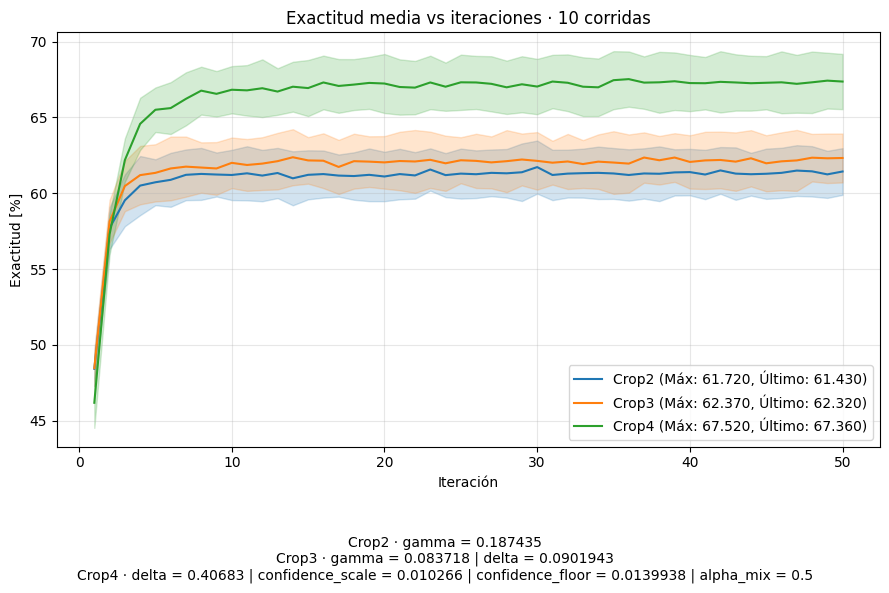

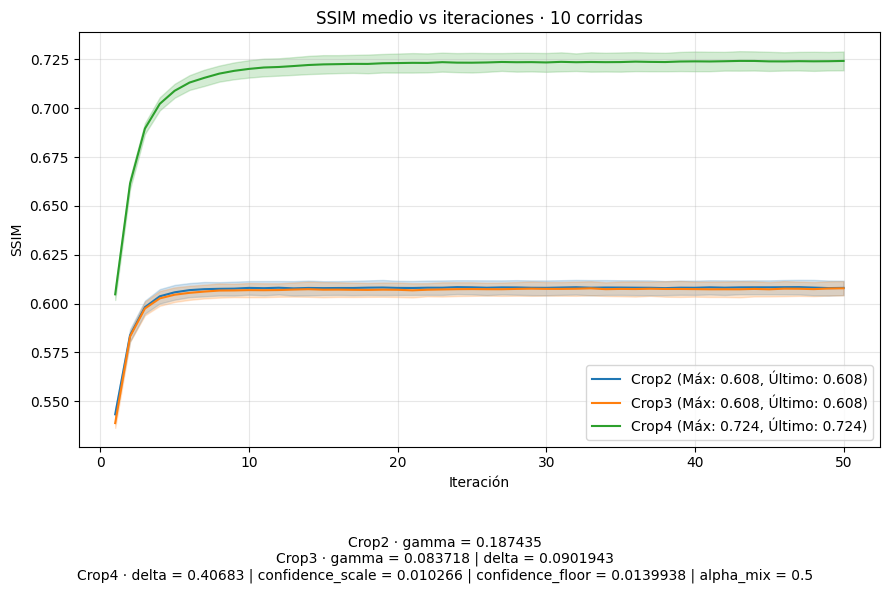

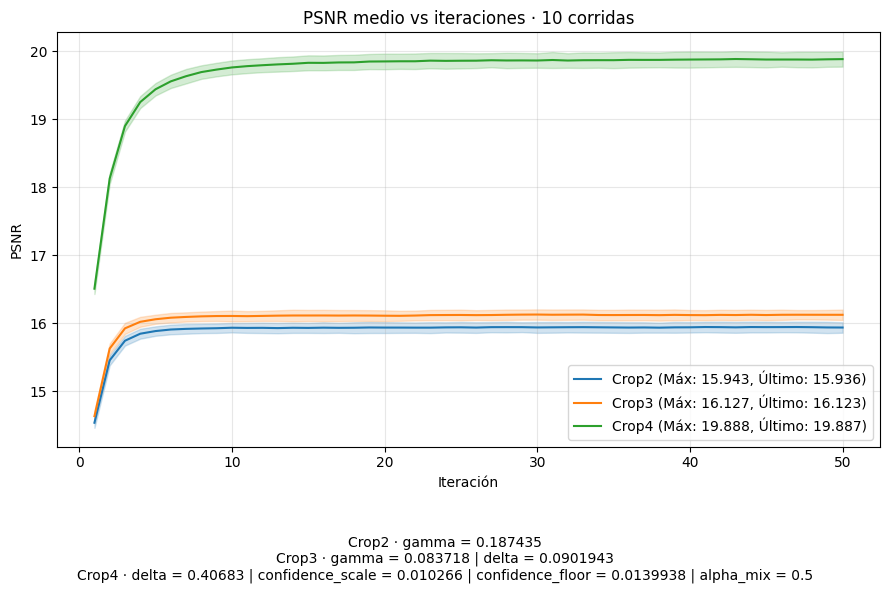

In [2]:
import numpy as np
import matplotlib.pyplot as plt

footer = "\n".join(
    f"{name} · " + " | ".join(f"{key} = {value:g}" for key, value in params.items())
    for name, params in params_by_name.items()
)
colors = ("tab:blue", "tab:orange", "tab:green")

for metric, title, ylabel in (
    ("acc", "Exactitud media", "Exactitud [%]"),
    ("ssim", "SSIM medio", "SSIM"),
    ("psnr", "PSNR medio", "PSNR"),
):
    fig, ax = plt.subplots(figsize=(9, 6))
    for name, color in zip(results_by_name, colors):
        results = results_by_name[name]
        mean = results[f"mean_{metric}"]
        std = results[f"std_{metric}"]
        if metric == "acc":
            mean = mean * 100
            std = std * 100
        x = np.arange(1, len(mean) + 1)
        ax.plot(
            x, mean, color=color,
            label=f"{name} (Máx: {mean.max():.3f}, Último: {mean[-1]:.3f})",
        )
        ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.2)

    ax.set_title(f"{title} vs iteraciones · {N_RUNS} corridas")
    ax.set_xlabel("Iteración")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.text(
        0.5, 0.02,
        footer,
        ha="center", va="bottom", fontsize=10,
    )
    fig.tight_layout(rect=(0, 0.15, 1, 1))
    plt.show()


## comparacion para optimizando ssim

In [3]:

import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../..")))
from project.loader import Loader
from project.CROP.models.crop2 import Crop2
from project.CROP.models.crop3 import Crop3
from project.CROP.models.crop4 import Crop4
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random

SEED = 3333

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATASET = "fashion" 
LAT = 64
INTER = 256


cvae = Loader.cvae(model_name=f"int_{INTER}_lat_{LAT}_{DATASET}.keras")

data = Loader.data(dataset=DATASET)

predictor = Loader.predictor(model_name=f"CCE_Conv2D_{DATASET}.keras")

N_RUNS = 10

ITERATIONS = 50
N_PICTURES = 1000


params_by_name = {
    "Crop2": {"gamma": 0.8976688369616603},
    "Crop3": {"gamma": 0.8438622951406172, 'delta': 0.20333271616654783},
    "Crop4": { 
        "delta": 0.7484575455399347,
        "confidence_scale": 0.016679948674418854,
        "confidence_floor": 0.010314311115229178,
    },
}
models_by_name = {"Crop2": Crop2, "Crop3": Crop3, "Crop4": Crop4}
results_by_name = {
    name: {metric: [] for metric in ("acc", "ssim", "psnr")}
    for name in models_by_name
}

x_test = data["x_test"]
x_test_1 = data["x_test_1"]
y_test = data["y_test"]
y_test_1 = data["y_test_1"]
labels = data["labels"]

data_save_dir = os.path.join(
    os.path.dirname(Loader.BASE_DIR), "experiments", "crop3_comparation", "data"
)

for run in range(N_RUNS):
    print(f"Run {run + 1}/{N_RUNS}")

    idx0 = np.random.permutation(len(x_test))
    idx1 = np.random.permutation(len(x_test_1))
    X0 = x_test[idx0][:N_PICTURES]
    Y0 = y_test[idx0][:N_PICTURES]
    X1 = x_test_1[idx1][:N_PICTURES]
    Y1 = y_test_1[idx1][:N_PICTURES]

    for name, model in models_by_name.items():
        print(name)
        crop = model(cvae=cvae, predictor=predictor)
        metrics = crop.unmix(
            X0,
            X1,
            Y0,
            Y1,
            data_save_dir=data_save_dir,
            notebook_name="comparison_copy",
            iterations=ITERATIONS,
            show_image=False,
            labels=labels,
            params=params_by_name[name],
            run_metadata={"dataset": DATASET, "seed": SEED, "run": run + 1, "variant": name},
            save_all_curves=True,
        )
        for metric, key in (
            ("acc", "acc_both_plot"),
            ("ssim", "ssim_plot"),
            ("psnr", "psnr_plot"),
        ):
            results_by_name[name][metric].append(metrics[key])

for results in results_by_name.values():
    for metric in ("acc", "ssim", "psnr"):
        results[metric] = np.asarray(results[metric])
        results[f"mean_{metric}"] = results[metric].mean(axis=0)
        results[f"std_{metric}"] = results[metric].std(axis=0)


Usando fashion como dataset
Run 1/10
Crop2

======= PARÁMETROS DEL MODELO =====================
alpha_1     : -2.000
alpha_2     : -22.000
bias        : 0.220
slope       : 22.000
gamma       : 0.898
alpha_mix   : 0.500
beta        : 1.000
iteraciones : 10.000

============= MÉTRICAS ===========================
recon_bpsnr      : mean: 17.552  std:3.166
mask_bpsnr       : mean: 10.929  std:1.873
ssim             : mean: 0.649  std:0.137
acc_at_least_one : 0.957
acc_both         : 0.580

Crop3

======= PARÁMETROS DEL MODELO =====================
alpha_1     : -2.000
alpha_2     : -22.000
bias        : 0.220
slope       : 22.000
gamma       : 0.844
alpha_mix   : 0.500
beta        : 1.000
iteraciones : 10.000
delta       : 0.203

============= MÉTRICAS ===========================
recon_bpsnr      : mean: 17.701  std:3.343
mask_bpsnr       : mean: 10.660  std:1.931
ssim             : mean: 0.647  std:0.132
acc_at_least_one : 0.942
acc_both         : 0.545

Crop4

======= PARÁMETROS DEL MOD

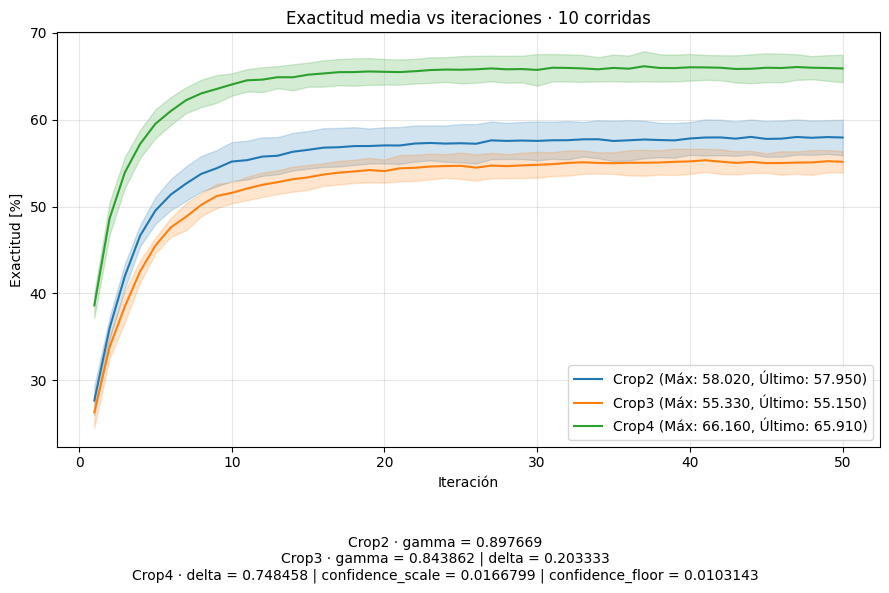

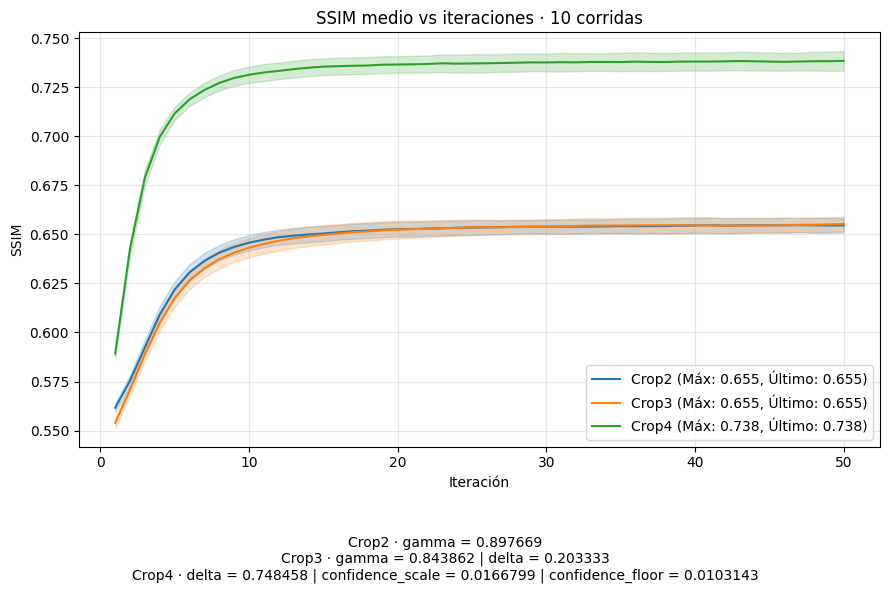

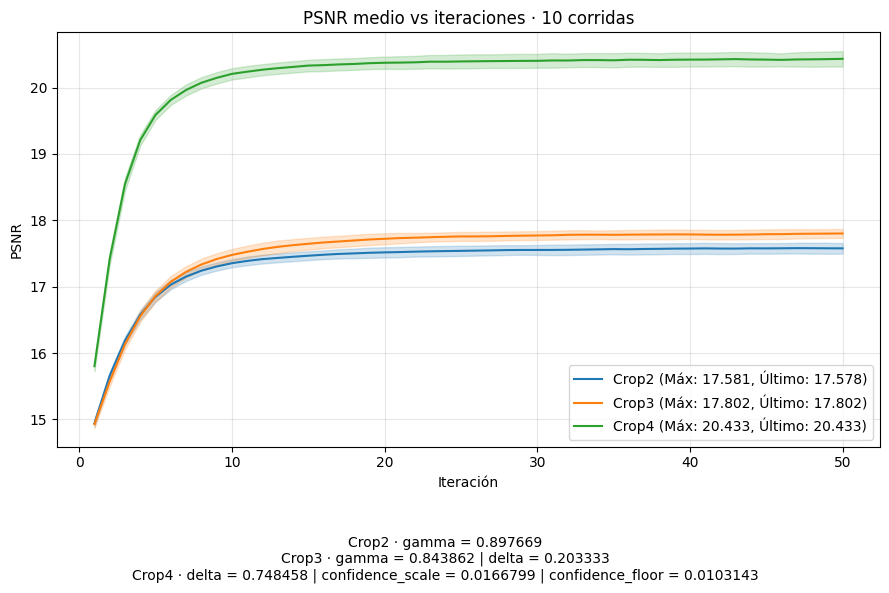

In [4]:
import numpy as np
import matplotlib.pyplot as plt

footer = "\n".join(
    f"{name} · " + " | ".join(f"{key} = {value:g}" for key, value in params.items())
    for name, params in params_by_name.items()
)
colors = ("tab:blue", "tab:orange", "tab:green")

for metric, title, ylabel in (
    ("acc", "Exactitud media", "Exactitud [%]"),
    ("ssim", "SSIM medio", "SSIM"),
    ("psnr", "PSNR medio", "PSNR"),
):
    fig, ax = plt.subplots(figsize=(9, 6))
    for name, color in zip(results_by_name, colors):
        results = results_by_name[name]
        mean = results[f"mean_{metric}"]
        std = results[f"std_{metric}"]
        if metric == "acc":
            mean = mean * 100
            std = std * 100
        x = np.arange(1, len(mean) + 1)
        ax.plot(
            x, mean, color=color,
            label=f"{name} (Máx: {mean.max():.3f}, Último: {mean[-1]:.3f})",
        )
        ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.2)

    ax.set_title(f"{title} vs iteraciones · {N_RUNS} corridas")
    ax.set_xlabel("Iteración")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.text(
        0.5, 0.02,
        footer,
        ha="center", va="bottom", fontsize=10,
    )
    fig.tight_layout(rect=(0, 0.15, 1, 1))
    plt.show()
